# 01 · One fair test for every model: the shared split and the classical baselines

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/LSTM_passenges_prediction/blob/main/notebooks/01_shared_split_and_classical_baselines.ipynb)

**What this notebook does.** In 2023 I tried to forecast the monthly number of airline passengers with an LSTM. The notebook stopped with an error and never
produced a forecast (see [`legacy/ABOUT.md`](../legacy/ABOUT.md)). Today we start over with a *fair* setup: **one time-ordered split of the data and one set of rules that every model must obey**,
and we begin with the models that were there long before neural networks: simple baselines, ARIMA, exponential smoothing and Prophet.
Notebook 02 adds an LSTM and a small Transformer to the same test.

*Time: about 10 minutes (everything runs in a few minutes on a laptop CPU). Prerequisite: none.*

## 1 · Then versus now

| | **Then (January 2023, in [`legacy/`](../legacy))** | **Now** |
|---|---|---|
| Result | the training cell stops with a `ValueError`; no forecast was ever produced | forecasts and a results table for every model, on the same test months |
| Input | a model built for 143 features per step (143 is the *length of the series*) | one value per month, windows or full history depending on the model |
| Target | the target of each window is the last value *inside* the window (target leakage) | a model only ever sees data strictly before the month it predicts, enforced and tested in code |
| Data | the first month is dropped (`iloc[1:]`), 143 of 144 months | all 144 months |
| Baseline | none | naive and seasonal-naive forecasts: the bar every model must clear |
| Evaluation | no metric in the original units | MAE, RMSE and MAPE in thousands of passengers (and percent), on a validation set for choices and a test set for the final grade |
| Seed and tests | none | fixed seed; smoke tests and a test that runs every notebook |

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once (and install Prophet).
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/LSTM_passenges_prediction.git"], check=True)
    os.chdir("LSTM_passenges_prediction/notebooks")

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import forecasting as fc
from src.forecasting import save_figure

np.random.seed(fc.SEED)            # (the classical models below are deterministic; the seed matters from notebook 02 on)
plt.rcParams["figure.dpi"] = 100

## 2 · The data

The monthly number of international airline passengers (in thousands) from January 1949 to December 1960: 144 months. See [`data/README.md`](../data/README.md) for the source and the licence note.

144 months from 1949-01 to 1960-12    missing values: 0
first values: [112, 118, 132, 129, 121]   last values: [606, 508, 461, 390, 432]


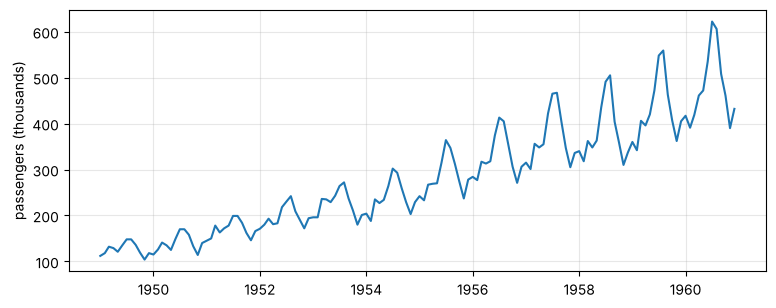

In [2]:
series = fc.load_series()
print(len(series), "months from", series.index[0].strftime("%Y-%m"), "to", series.index[-1].strftime("%Y-%m"), "   missing values:", int(series.isna().sum()))
print("first values:", series.iloc[:5].astype(int).tolist(), "  last values:", series.iloc[-5:].astype(int).tolist())

fig = fc.plot_series(series)
save_figure(fig, "01_series.png")
plt.show()

**What to notice.** Two things are visible by eye: a **rising trend** (about 4 times as many passengers in 1960 as in 1949) and a **yearly pattern** that repeats every 12 months,
with a swing that **grows with the level** (the summer peaks of the later years are much higher than those of the early years, in absolute numbers).
The second point matters: a model that adds a *fixed* seasonal swing will be too small late in the series; one that multiplies, or works with the logarithm, will not.

*Figure: monthly passengers (thousands), 1949 to 1960.*

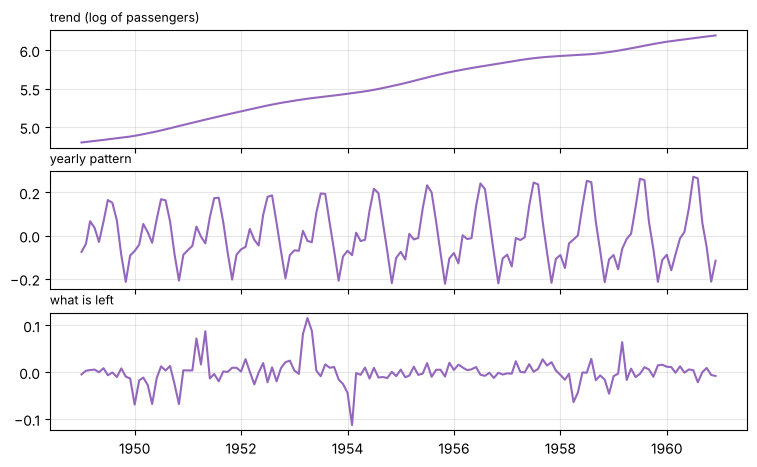

In [3]:
fig = fc.plot_decomposition(series)
save_figure(fig, "01_decomposition.png")
plt.show()

**What to notice.** The series was split into three parts (after taking logarithms, so that parts add up):

- **trend:** rises all the way, from about 4.8 to about 6.2 in logs, a factor of about ^{1.4}\approx 4$ in passengers;
- **yearly pattern:** after the logarithm the swing is about the *same size every year* (between about -0.2 and +0.27), which confirms that in the original numbers the swing grows with the level. This is why SARIMA below works with the logarithm;
- **what is left:** small (mostly within +/-0.05), with larger deviations in 1951 and in 1953 to 1954 (about +/-0.1).

*Figure: STL decomposition of the logarithm of the series into trend, yearly pattern and remainder.*

## 3 · The shared split and the rules

All models in this repository (this notebook and the next) are judged on **exactly the same months**:

- **train:** the first 96 months (1949 to 1956, 67% of the series, like the 67% of the first version);
- **validation:** the next 24 months (1957 and 1958): used to *choose* settings, never for the final grade;
- **test:** the last 24 months (1959 and 1960): used **once** at the end.

Rules that every model must follow (some are enforced by the code, see `src/forecasting.py` and the tests):

1. **Time order, no shuffling.** The future never leaks into the past.
2. **A forecast for a month may use only data from earlier months.**
3. **Choices (which ARIMA order, which Prophet mode) are made on the validation months only.**
4. **The test months are touched once**, after all choices are made.

We evaluate two tasks, because "forecasting" can mean two different things:

- **Task A, one month ahead (walk-forward):** for each of the 24 months, the model is given all true values before that month and predicts that single month. The classical models are re-fitted every time with the longer history.
- **Task B, 24 months ahead:** the model is given everything before the period and must predict all 24 months at once, without seeing any of them. This is much harder.

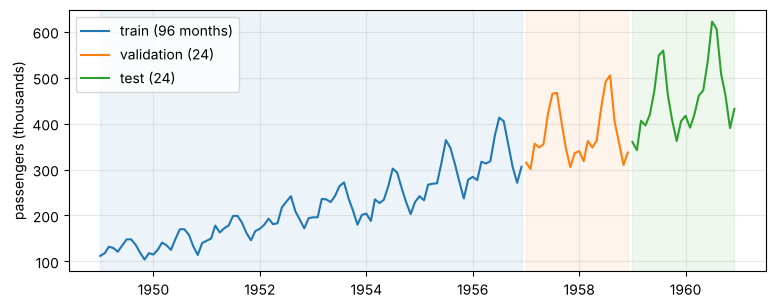

train       96 months   1949-01 to 1956-12
validation  24 months   1957-01 to 1958-12
test        24 months   1959-01 to 1960-12


In [4]:
fig = fc.plot_split(series)
save_figure(fig, "01_split.png")
plt.show()

train, validation, test = fc.split(series)
for name, part in [("train", train), ("validation", validation), ("test", test)]:
    print(f"{name:10s} {len(part):3d} months   {part.index[0].strftime('%Y-%m')} to {part.index[-1].strftime('%Y-%m')}")

**What to notice.** The three parts follow each other in time with no overlap. Because the series grows, the test months (the highest values of all) are *outside the range of the training data*: every model has to extrapolate.

*Figure: train, validation and test parts of the series.*

**Metrics (light math).** For $n$ test months with true values $y_t$ and forecasts $\hat y_t$:

$$\mathrm{MAE}=\frac1n\sum_t|y_t-\hat y_t| \qquad \mathrm{RMSE}=\sqrt{\frac1n\sum_t(y_t-\hat y_t)^2} \qquad \mathrm{MAPE}=\frac{100}{n}\sum_t\frac{|y_t-\hat y_t|}{y_t}$$

- MAE: the average miss, in thousands of passengers; RMSE: like MAE but big misses count more; MAPE: the average miss as a percentage of the true value (easy to read, but it punishes misses in low months more).

## 4 · Two baselines that any model must beat

- **Naive:** next month = this month.
- **Seasonal naive:** this month = the same month last year. For data with a strong yearly pattern this is a hard baseline to beat: a model that cannot beat it has learned nothing useful.

In [5]:
def evaluate(forecaster, part_start, part_length, task):
    run = fc.walk_forward if task == "A" else fc.multi_step
    return run(forecaster, series, part_start, part_length)

val_start = fc.N_TRAIN
baselines = {"naive": fc.naive, "seasonal naive": fc.seasonal_naive}
for name, forecaster in baselines.items():
    a = fc.scores(validation, evaluate(forecaster, val_start, fc.N_VAL, "A"))
    b = fc.scores(validation, evaluate(forecaster, val_start, fc.N_VAL, "B"))
    print(f"{name:15s} validation  task A: MAE {a['MAE']:5.1f}  MAPE {a['MAPE %']:4.1f}%    task B: MAE {b['MAE']:5.1f}  MAPE {b['MAPE %']:4.1f}%")

naive           validation  task A: MAE  35.9  MAPE  9.5%    task B: MAE  69.2  MAPE 16.6%
seasonal naive  validation  task A: MAE  26.4  MAPE  6.9%    task B: MAE  46.5  MAPE 12.2%


**What to notice.** On the validation months the seasonal-naive forecast is much better than the naive one (task A: MAE 26.4 versus 35.9; task B: 46.5 versus 69.2): the yearly pattern is strong, and "same month last year" uses it. These are the numbers any model must beat.
Both baselines are *biased low* when a series grows: last year's value is smaller than this year's.

## 5 · The classical models

- **SARIMA** (seasonal ARIMA, Box and Jenkins): predicts the next value from the last values, the last errors and the same months of earlier years, after taking *differences* (the change from one month, and from the same month last year) to remove trend and seasonality.
  We fit it to the **logarithm** of the series, because the seasonal swing grows with the level. We try four orders (an order says how many past values and past errors are used).
- **Holt-Winters exponential smoothing:** keeps a running estimate of the level, the trend and the 12 seasonal factors, updating them month by month. We try three variants.
- **Prophet** (Taylor and Letham, 2018): fits a smooth trend plus a yearly seasonal curve in one optimisation. We try an additive and a multiplicative seasonality.

For every family we pick the variant with the best **validation** MAE, separately for each task. Some variants may fail; a variant that produces non-finite numbers is disqualified.

In [6]:
candidates = {
    "SARIMA(0,1,1)(0,1,1)": fc.sarima((0, 1, 1), (0, 1, 1)),
    "SARIMA(1,1,1)(0,1,1)": fc.sarima((1, 1, 1), (0, 1, 1)),
    "SARIMA(1,1,0)(0,1,1)": fc.sarima((1, 1, 0), (0, 1, 1)),
    "SARIMA(2,1,1)(0,1,1)": fc.sarima((2, 1, 1), (0, 1, 1)),
    "Holt-Winters add/add": fc.holt_winters("add", "add"),
    "Holt-Winters add/mul": fc.holt_winters("add", "mul"),
    "Holt-Winters damped/mul": fc.holt_winters("add", "mul", damped=True),
    "Prophet additive": fc.prophet("additive"),
    "Prophet multiplicative": fc.prophet("multiplicative"),
}
families = {"SARIMA": [k for k in candidates if k.startswith("SARIMA")],
            "Holt-Winters": [k for k in candidates if k.startswith("Holt")],
            "Prophet": [k for k in candidates if k.startswith("Prophet")]}

start = time.time()
validation_scores = {}
print(f"{'variant':25s} {'task A: MAE':>12s} {'task B: MAE':>12s}")
for name, forecaster in candidates.items():
    a = fc.scores(validation, evaluate(forecaster, val_start, fc.N_VAL, "A"))["MAE"]
    b = fc.scores(validation, evaluate(forecaster, val_start, fc.N_VAL, "B"))["MAE"]
    validation_scores[name] = {"A": a, "B": b}
    print(f"{name:25s} {a:12.1f} {b:12.1f}")
print(f"({time.time() - start:.0f} s)")

variant                    task A: MAE  task B: MAE


SARIMA(0,1,1)(0,1,1)               9.8         22.2


SARIMA(1,1,1)(0,1,1)               9.5         24.3


SARIMA(1,1,0)(0,1,1)               9.4         21.2


SARIMA(2,1,1)(0,1,1)               nan        283.6


Holt-Winters add/add              13.9         16.3


Holt-Winters add/mul               8.8         14.6


Holt-Winters damped/mul            8.5         18.2


Prophet additive                  31.2         33.8


Prophet multiplicative            16.4         23.6
(29 s)


**What to notice** (validation months 1957 and 1958; MAE in thousands of passengers; baselines: seasonal naive 26.4 in task A and 46.5 in task B):

- Most classical variants beat the baselines by a wide margin; the best reach 8.5 in task A and 14.6 in task B, about one third of the seasonal-naive error. **Not all do:** Prophet with additive seasonality (31.2 in task A) is worse than seasonal naive (26.4).
- **Multiplicative beats additive** for both Holt-Winters (8.8 versus 13.9 in task A) and Prophet (16.4 versus 31.2): the growing seasonal swing again.
- **SARIMA(2,1,1)(0,1,1) failed:** it produced non-finite numbers in task A and exploding forecasts in task B (MAE 283.6). Optimising a more flexible model on 96 months can fail, and we report it instead of hiding it.
- The ranking depends on the task: for Holt-Winters the damped trend is best in task A (8.5) but worst of the multiplicative variants in task B (18.2 versus 14.6).

In [7]:
chosen = {"A": {}, "B": {}}
for task in ("A", "B"):
    for family, names in families.items():
        usable = [n for n in names if np.isfinite(validation_scores[n][task]) and validation_scores[n][task] < 1000]
        chosen[task][family] = min(usable, key=lambda n: validation_scores[n][task])
for task in ("A", "B"):
    print(f"task {task}:", chosen[task])

task A: {'SARIMA': 'SARIMA(1,1,0)(0,1,1)', 'Holt-Winters': 'Holt-Winters damped/mul', 'Prophet': 'Prophet multiplicative'}
task B: {'SARIMA': 'SARIMA(1,1,0)(0,1,1)', 'Holt-Winters': 'Holt-Winters add/mul', 'Prophet': 'Prophet multiplicative'}


**What to notice.** Task A: SARIMA(1,1,0)(0,1,1), Holt-Winters with a damped trend and multiplicative seasonality, Prophet multiplicative. Task B: the same SARIMA and Prophet, but Holt-Winters *without* damping. Each choice used the validation months only.

### Check yourself

1. Why do we pick the ARIMA order on the validation months and not on the test months?
2. Why is task B harder than task A, and what does that mean for the size of the errors we expect?

<details>
<summary>Answers</summary>


1. If we picked the best order on the test months, the test result would no longer be an independent exam: it would measure how well we chose, not how well the model forecasts new data.
2. In task A the model gets the true value of last month before each forecast; in task B it must forecast up to 24 months ahead without any new information, so errors accumulate and are expected to be larger.

</details>

## 6 · The final grade: the test months, used once

Now, with all choices made, the test months (1959 and 1960). For task B the models see everything up to the end of 1958 (train and validation together).

In [8]:
test_start = fc.N_TRAIN + fc.N_VAL
predictions = {"A": {}, "B": {}}
results = []
start = time.time()
for task in ("A", "B"):
    for label, forecaster in {"naive": fc.naive, "seasonal naive": fc.seasonal_naive,
                              **{f"{family}": candidates[name] for family, name in chosen[task].items()}}.items():
        predicted = evaluate(forecaster, test_start, fc.N_TEST, task)
        predictions[task][label] = predicted
        results.append({"task": task, "model": label, **fc.scores(test, predicted)})
print(f"({time.time() - start:.0f} s)")

table = pd.DataFrame(results).set_index(["task", "model"]).round(1)
print(table.to_string())

(5 s)
                       MAE   RMSE  MAPE %
task model                               
A    naive            44.2   51.8     9.7
     seasonal naive   47.6   50.0    10.5
     SARIMA           12.5   15.8     2.8
     Holt-Winters     12.2   16.0     2.7
     Prophet          17.6   21.9     3.8
B    naive           115.2  137.3    23.6
     seasonal naive   71.2   77.0    15.5
     SARIMA           42.0   45.7     9.1
     Holt-Winters     29.0   32.5     6.4
     Prophet          25.5   30.6     5.4


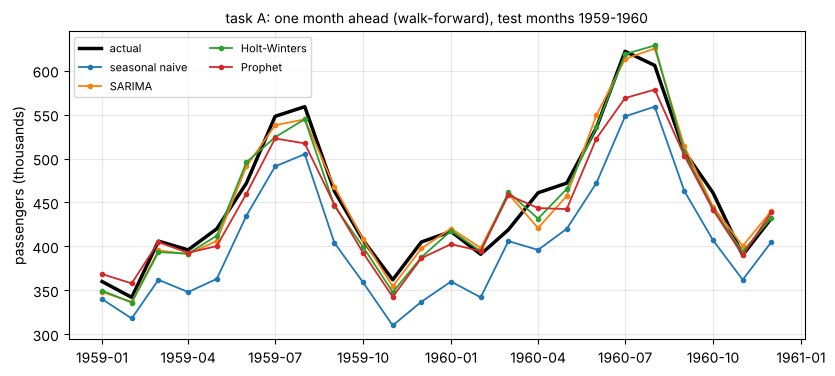

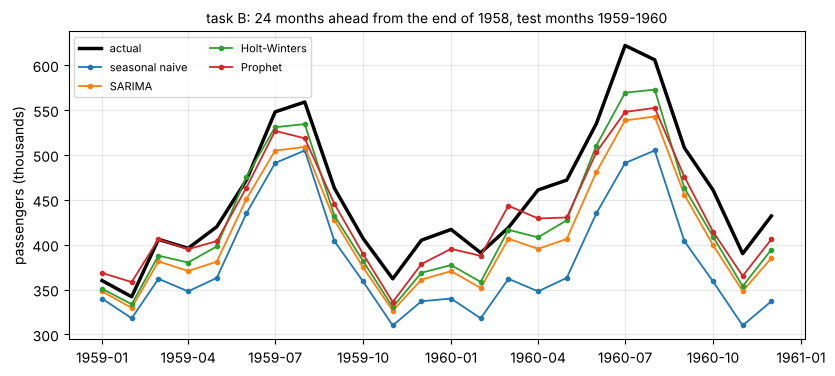

In [9]:
for task, title in [("A", "task A: one month ahead (walk-forward), test months 1959-1960"),
                    ("B", "task B: 24 months ahead from the end of 1958, test months 1959-1960")]:
    shown = {k: v for k, v in predictions[task].items() if k != "naive"}
    fig = fc.plot_forecasts(test, shown, title)
    save_figure(fig, f"01_forecasts_task_{task.lower()}.png")
    plt.show()

**What to notice** (test months 1959 and 1960, never used for a choice; MAE and RMSE in thousands of passengers):

| Task | Model | MAE | RMSE | MAPE |
|---|---|---|---|---|
| A (one month ahead) | naive | 44.2 | 51.8 | 9.7% |
| | seasonal naive | 47.6 | 50.0 | 10.5% |
| | SARIMA | 12.5 | 15.8 | 2.8% |
| | Holt-Winters | 12.2 | 16.0 | 2.7% |
| | Prophet | 17.6 | 21.9 | 3.8% |
| B (24 months ahead) | naive | 115.2 | 137.3 | 23.6% |
| | seasonal naive | 71.2 | 77.0 | 15.5% |
| | SARIMA | 42.0 | 45.7 | 9.1% |
| | Holt-Winters | 29.0 | 32.5 | 6.4% |
| | Prophet | 25.5 | 30.6 | 5.4% |

- **Task A:** SARIMA (12.5) and Holt-Winters (12.2) are practically tied, about 3.5 to 4 times better than the baselines; Prophet (17.6) is behind. The difference between the first two is far too small to rank them on 24 test months.
- **Seasonal naive is slightly *worse* than naive on the test months** (47.6 versus 44.2 MAE in task A), although it was much better on the validation months. In the figure its forecasts sit clearly below the actual values: the series grew, so "last year" is too low.
- **Task B is much harder:** all errors are two to three times larger, and the ranking changes: Prophet is the best (25.5), then Holt-Winters (29.0), then SARIMA (42.0). All three underestimate the very high summer peak of 1960, as the figure shows.
- Which model is "best" thus depends on the question (one month or two years ahead), and with 24 test months small gaps mean little.

*Figures: forecasts and actual values on the test months for task A (one month ahead, walk-forward) and task B (24 months ahead).*

## 7 · Looking inside the Prophet model

Prophet is built from *parts* we can look at: a trend and a yearly pattern. Fitted on train and validation together:

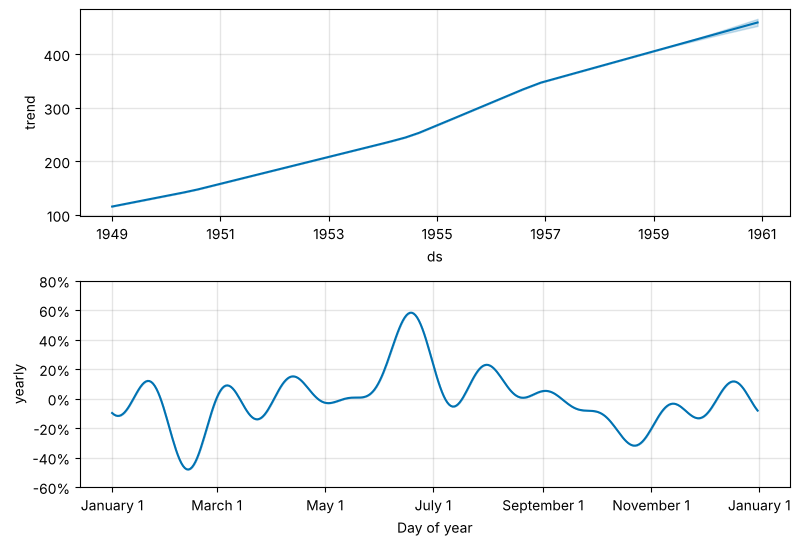

yearly pattern (share of the trend, by month): {1: -0.09, 2: -0.13, 3: 0.0, 4: -0.03, 5: -0.03, 6: 0.12, 7: 0.24, 8: 0.23, 9: 0.05, 10: -0.09, 11: -0.21, 12: -0.12}
highest month: 7   lowest month: 11


In [10]:
import logging
logging.getLogger("prophet.plot").setLevel(logging.CRITICAL)
from prophet import Prophet
fc.quiet_prophet_logs()
history = pd.concat(fc.split(series)[:2])
model = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False, seasonality_mode="multiplicative")
model.fit(pd.DataFrame({"ds": history.index, "y": history.to_numpy()}))
components = model.predict(model.make_future_dataframe(periods=24, freq="MS"))

fig = model.plot_components(components)
fig.set_size_inches(8, 5.5)
save_figure(fig, "01_prophet_components.png")
plt.show()

yearly = components.assign(month=components["ds"].dt.month).groupby("month")["yearly"].mean()
print("yearly pattern (share of the trend, by month):", {int(m): round(float(v), 2) for m, v in yearly.items()})
print("highest month:", int(yearly.idxmax()), "  lowest month:", int(yearly.idxmin()))

**What to notice.**

- **Trend:** a piecewise-linear curve; after about 1957 it is a straight line, so the model keeps adding the growth rate of the last years, which is smaller than the growth of 1960, consistent with the forecasts that fall short in the figure of task B.
- **Yearly pattern** (as a share of the trend, averaged by month): the **highest month is July (+0.24)** and August (+0.23) is almost as high; the **lowest is November (-0.21)**, with February (-0.13) and December (-0.12) also low.
- The curve between the months wiggles (for example a dip around the end of February and several small bumps). With only twelve data points per year to fit a flexible curve, such wiggles are artefacts; we do not read meaning into them.

*Figure: Prophet's trend (top) and yearly pattern (bottom) fitted on the train and validation months.*

## 8 · Common mistakes (and where the first version fell into them)

- **No baseline.** A model's error means nothing until you know what "repeat last year" achieves.
- **Target leakage.** If the target is part of the input window, almost any model looks brilliant. Always check what the model can see.
- **Shuffling a time series** before splitting, or choosing settings on the test months.
- **Judging by one number.** Look at the forecast plot as well: a single metric can hide a model that is systematically too low at the end.
- **Ignoring the scale of the seasonality.** The swing grows with the level here; models that assume a fixed swing fall behind.

## 9 · Recap

- One time-ordered split and a few strict rules make every comparison in this repository fair.
- Simple baselines are strong on this series, and classical models with the right seasonal structure are stronger still.
- These are the numbers the neural models of notebook 02 have to beat; if they cannot, the honest conclusion is that they are not needed here.

**Next:** notebook 02 trains an LSTM and a small Transformer on the same split and adds them to the same table.